# Phase 3.1 preprocessing lab

This notebook is an experimental interface to the real SCR lane-detection code.

**RULES**
1. The `.py` files are the single source of truth.
2. Do not copy algorithm implementations into this notebook.
3. Temporary experiments belong here.
4. Permanent accepted parameter values must be changed manually in `tuning.py`.
5. Runtime code must remain independent of Jupyter.

This lab ends at binary BEV. It starts no application processes and sends no vehicle commands. Use a development kernel with NumPy, OpenCV, Matplotlib and IPython/Jupyter installed. These are notebook dependencies, not new car runtime dependencies.

## Setup and autoreload

`%autoreload 2` reloads edited project modules before a cell runs. After saving a `.py` change, rerun the setup/harness and stage cells from the top so intermediate arrays are recomputed. The project root is discovered from the kernel's working directory; start Jupyter in SCRbrain or its notebooks directory.

In [5]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src/algorithms/LaneDetection/utils/preprocessing.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start the notebook kernel from SCRbrain or SCRbrain/notebooks.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.algorithms.LaneDetection.utils.preprocessing import PreprocessingMixin
from src.algorithms.LaneDetection.utils import tuning
print("Project root:", PROJECT_ROOT)

import sys
print(sys.executable)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Project root: c:\Data\Projects\SCR-proiect\NeuroDrive-BFMC2026-main -modifiedForSCR\SCR\SCRbrain
c:\Data\PythonEnvs\scr-preprocessing\Scripts\python.exe


## Image configuration

Paths below are relative to **SCRbrain**, independent of whether Jupyter starts in its root or notebooks folder. Put a real 512x270 camera image in `test_images/lane_test.jpg`, then set `USE_SYNTHETIC = False`. Synthetic mode is enabled initially so a fresh checkout can run; it only checks execution and cannot establish real-camera quality. Images of other dimensions are rejected rather than silently resized.

In [6]:
IMAGE_PATH = "test_images/lane_test.jpg"  # Repository-relative; no personal paths.
USE_SYNTHETIC = True                    # Set False for real camera testing.
MASK_PREVIEW = True                     # Display optional masking without changing tuning.

## Notebook-only observation harness

The helper records data passed between the real methods, then delegates immediately to the mixin. It implements no preprocessing mathematics. This allows inspection of grayscale (created inside the runtime pipeline) and the raw threshold image (passed into runtime morphology), even though those stages have no standalone public API.

In [7]:
class PreprocessingTester(PreprocessingMixin):
    def get_birdseye_responsive_gray(self, gray_img, *args, **kwargs):
        self.observed_gray = gray_img.copy()
        return super().get_birdseye_responsive_gray(gray_img, *args, **kwargs)

    def _apply_threshold_morphology(self, binary):
        self.observed_threshold = binary.copy()
        return super()._apply_threshold_morphology(binary)

processor = PreprocessingTester()

# Display helpers only: BGR -> RGB is for Matplotlib, never for preprocessing.
def show_images(items):
    fig, axes = plt.subplots(1, len(items), figsize=(6 * len(items), 4), squeeze=False)
    for ax, (title, image) in zip(axes[0], items):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=1 if image.max() <= 1 else 255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def show_tuning(prefixes):
    for name in sorted(vars(tuning)):
        if name.startswith(prefixes):
            print(f"{name} = {getattr(tuning, name)}")

## Step 1 — Original BGR image

Input is a local OpenCV image or optional deterministic synthetic data. The output remains a 270x512 uint8 BGR array. Only display uses RGB. The synthetic lines have no role in the algorithm.

SYNTHETIC test image: execution check only, not real-road validation.
shape: (270, 512, 3) dtype: uint8


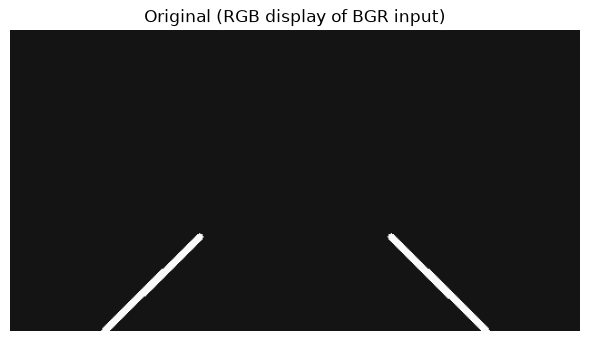

In [8]:
image_file = PROJECT_ROOT / IMAGE_PATH
if USE_SYNTHETIC:
    frame_bgr = np.full((270, 512, 3), 20, dtype=np.uint8)
    cv2.line(frame_bgr, (170, 185), (85, 269), (250, 250, 250), 5)
    cv2.line(frame_bgr, (342, 185), (427, 269), (250, 250, 250), 5)
    print("SYNTHETIC test image: execution check only, not real-road validation.")
else:
    frame_bgr = cv2.imread(str(image_file), cv2.IMREAD_COLOR)
    if frame_bgr is None:
        raise FileNotFoundError(f"Could not read test image: {image_file}. Place a camera image there or enable USE_SYNTHETIC.")
if frame_bgr.shape != (270, 512, 3) or frame_bgr.dtype != np.uint8:
    raise ValueError(f"Expected 270x512 uint8 BGR; got {frame_bgr.shape}, {frame_bgr.dtype}")
print("shape:", frame_bgr.shape, "dtype:", frame_bgr.dtype)
show_images([("Original (RGB display of BGR input)", frame_bgr)])

## Step 2 — Grayscale

Input: BGR camera frame. Output: one intensity channel. The runtime's `preprocess_frame_bgr()` owns the conversion; the harness observes its input to BEV rather than duplicating grayscale logic. Grayscale removes channel handling from illumination/threshold operations. This step has no separate tuning parameter.

grayscale: (270, 512) uint8


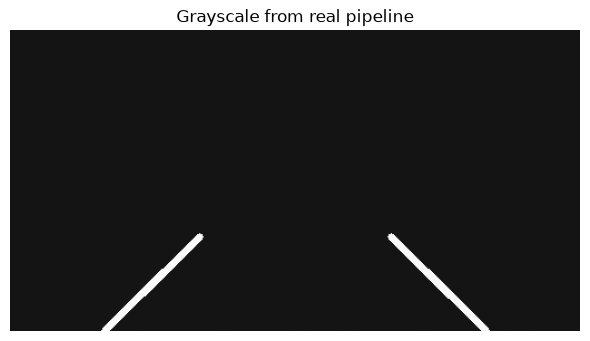

In [9]:
# Execute the real pipeline to observe the grayscale array at its BEV boundary.
processor.preprocess_frame_bgr(frame_bgr)
gray = processor.observed_gray.copy()
print("grayscale:", gray.shape, gray.dtype)
show_images([("Grayscale from real pipeline", gray)])

## Step 3 — Bird's-Eye View

Input: grayscale. Output: warped grayscale at the same dimensions, plus forward/inverse matrices. The source trapezoid and destination margins come from current tuning. All point/matrix/warp calculations stay in `get_birdseye_responsive_gray()`.

In [ ]:
show_tuning(("BEV_SRC_", "BEV_DST_"))
bev_gray, matrix, inverse, src_points, dst_points = processor.get_birdseye_responsive_gray(
    gray,
    top_width_factor=tuning.BEV_SRC_TOP_WIDTH_FACTOR,
    bottom_width_factor=tuning.BEV_SRC_BOTTOM_WIDTH_FACTOR,
    bottom_offset_factor=tuning.BEV_SRC_BOTTOM_OFFSET_FACTOR,
    horizon_factor=tuning.BEV_SRC_HORIZON_FACTOR,
    empty_margins=tuning.BEV_DST_EMPTY_MARGINS,
    return_points=True,
)
print("Source points:\n", src_points, "\nDestination points:\n", dst_points)
show_images([("Grayscale", gray), ("BEV grayscale", bev_gray)])

## Step 4 — Optional vehicle/front mask

Input/output: BEV grayscale. The real helper fills the configured lower-center trapezoid with black. Runtime currently disables it. A preview may show the enabled appearance without changing any tuning value; `bev_for_threshold` follows the actual enable flag. Keep preview separate from runtime equality checks.

In [ ]:
show_tuning(("BEV_BLACK_TRAPEZOID_",))
if MASK_PREVIEW or tuning.BEV_BLACK_TRAPEZOID_ENABLE:
    masked_preview = processor.apply_bev_black_trapezoid(
        bev_gray,
        top_width_frac=tuning.BEV_BLACK_TRAPEZOID_TOP_WIDTH_FRAC,
        bottom_width_frac=tuning.BEV_BLACK_TRAPEZOID_BOTTOM_WIDTH_FRAC,
        top_y_frac=tuning.BEV_BLACK_TRAPEZOID_TOP_Y_FRAC,
        bottom_y_frac=tuning.BEV_BLACK_TRAPEZOID_BOTTOM_Y_FRAC,
        center_x_frac=tuning.BEV_BLACK_TRAPEZOID_CENTER_X_FRAC,
    )
    show_images([("Unmasked BEV", bev_gray), ("Mask preview", masked_preview)])
bev_for_threshold = masked_preview if tuning.BEV_BLACK_TRAPEZOID_ENABLE else bev_gray
print("Runtime masking enabled:", tuning.BEV_BLACK_TRAPEZOID_ENABLE)

## Step 5 — Top-Hat / illumination preprocessing

Input: BEV grayscale selected by the runtime mask setting. Output: enhanced intensity image. The real helper handles blur and Top-Hat using current enable, blur and kernel settings. It emphasizes narrow bright markings against broader illumination changes. This displayed image is not passed into thresholding a second time: the real threshold method performs Top-Hat internally.

In [ ]:
show_tuning(("THRESH_TOPHAT_", "THRESH_GAUSSIAN_"))
tophat = processor._apply_tophat_prethreshold(bev_for_threshold)
show_images([("BEV used by runtime", bev_for_threshold), ("Top-Hat", tophat)])

## Step 6 — Global percentile threshold

Input: BEV grayscale, **not the already enhanced display array**. Output: the raw 0/1 threshold mask and the method's cleaned result. `_dynamic_percentile_binary()` owns Top-Hat, percentile statistics, offset, floor and morphology. The harness observes its raw input to morphology so there is no copied threshold calculation. Statistics use the lower ROI; thresholding applies to the full BEV. No polynomial guidance is used.

In [ ]:
show_tuning(("THRESH_PERCENTILE", "THRESH_OFFSET", "THRESH_ROI_", "THRESH_TOPHAT_STATS_", "THRESH_TOPHAT_MIN_"))
threshold_with_cleanup = processor._dynamic_percentile_binary(bev_for_threshold)
raw_threshold = processor.observed_threshold.copy()
print("Actual threshold diagnostics:", processor._last_threshold_debug)
show_images([("Top-Hat display", tophat), ("Raw global threshold (0/1)", raw_threshold)])

## Step 7 — Morphological cleanup

Input: the observed raw threshold mask. Output: cleaned uint8 0/1 binary BEV. Call the real morphology helper on that raw mask, avoiding a second cleanup of already cleaned output. Opening and rectangular closing use the imported enable/kernel/iteration settings.

In [ ]:
show_tuning(("THRESH_OPEN_", "THRESH_CLOSE_"))
manual_final = processor._apply_threshold_morphology(raw_threshold)
assert np.array_equal(manual_final, threshold_with_cleanup)
show_images([("Raw threshold", raw_threshold), ("Morphological cleanup", manual_final)])

## Step 8 — Complete runtime output and consistency

Run the exact `preprocess_frame_bgr()` entry point used by LaneDetection. Compare the stepped result with its output. A mismatch after edits means the stepped calls need review or earlier cells need rerunning; never force equality. Pixel statistics describe foreground occupancy, not lane detection or driving confidence.

In [ ]:
pipeline_final = processor.preprocess_frame_bgr(frame_bgr)
match = np.array_equal(manual_final, pipeline_final)
print("Step-by-step result matches runtime preprocessing:", match)
assert match, "Rerun all stages; review step calls against the current runtime implementation."
print("shape:", pipeline_final.shape, "dtype:", pipeline_final.dtype)
print("minimum:", pipeline_final.min(), "maximum:", pipeline_final.max())
foreground = np.count_nonzero(pipeline_final)
print("non-zero pixels:", foreground)
print(f"foreground percentage: {100 * foreground / pipeline_final.size:.2f}%")
show_images([("Stepwise binary BEV", manual_final), ("Runtime binary BEV", pipeline_final)])

# Temporary Parameter Experiments

The real preprocessing module reads `tuning` dynamically, so temporary module-attribute changes affect the actual pipeline. The experiment below tests the active global percentile parameter and restores it in `finally`, even if processing or plotting fails. It does not write any file. Use this only in the notebook kernel; do not run concurrent project processing in that kernel during an experiment.

After choosing an accepted value, edit `tuning.py` manually, save, and rerun the notebook from setup. The threshold floor may make several tested values look identical; that is a valid result, not proof that tuning was ignored.

In [ ]:
test_values = [80, 90, 95]
original_percentile = tuning.THRESH_PERCENTILE
experiment_images = []
try:
    for value in test_values:
        tuning.THRESH_PERCENTILE = value
        result = processor.preprocess_frame_bgr(frame_bgr)
        debug = dict(processor._last_threshold_debug)
        print(f"percentile={value}: threshold={debug['global_t']:.2f}, foreground={100 * np.count_nonzero(result) / result.size:.2f}%")
        experiment_images.append((f"Percentile {value}", result.copy()))
    show_images(experiment_images)
finally:
    tuning.THRESH_PERCENTILE = original_percentile
assert tuning.THRESH_PERCENTILE == original_percentile
restored = processor.preprocess_frame_bgr(frame_bgr)
assert np.array_equal(restored, pipeline_final)
print("Restored THRESH_PERCENTILE:", tuning.THRESH_PERCENTILE)

## End of Phase 3.1 study

All output stops at binary BEV. Place real camera images in `SCRbrain/test_images/` (create that folder locally) and rerun with synthetic mode disabled. Keep `.py` implementations and permanent tuning as the only source of truth. No lane search, fitting or vehicle control is performed here.